# STAT 578 Mini-Project II — Part 2 (Probe) and Part 3 (Connect)

**Setup.** CIFAR-10. ViT encoder: dim 192, depth 6, 3 heads, 4×4 patches, so $N = 64$. Light decoder: dim 96, depth 2. AdamW (lr 1.5e-3, wd 0.05), 10 warm-up epochs then cosine decay, batch 256. **Every run is 100 epochs with seed 0** (`torch.manual_seed(0)`), one run per configuration.

**Linear probe.** The encoder is frozen and the features standardised. A linear classifier is trained with AdamW for 40 epochs, and we report CIFAR-10 test accuracy.
- **Mean pooling is the headline number for every run**, since the assignment asks for one pooling choice used consistently. CLS pooling is shown alongside.
- The probe itself is not seeded: re-probing the same checkpoint moved accuracy by up to 0.2 points.
- Run-to-run noise from the pretraining seed is about 1–2 points.

| run | target | masking $\pi$ | role |
|---|---|---|---|
| `mae_r0.15`, `mae_r0.50`, `mae_r0.90` | pixel | random, ratio 0.15 / 0.50 / 0.90 | ratio sweep (2a) |
| `mae75` | pixel | random, 0.75 | Part 1 reference; ratio = 0.75 and pattern = random |
| `mae_block`, `mae_grid` | pixel | block / grid, 0.75 | pattern comparison (2a) |
| `feat75` | feature (EMA teacher, centered) | random, 0.75 | Part 1 reference |
| `feat_nocenter` | feature, `--no_center` | random, 0.75 | collapse ablation (2b) |

All numbers below are recomputed from `runs/*/metrics.csv` and `runs/part2_probe_results.csv`. The figures in `figures/` are regenerated by `python make_figures.py`, which is the one-command reproduction.

In [1]:
import os, re, copy
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader
from IPython.display import Image, display

import make_figures            # sets the Agg backend; switch back to inline below
import masking, data, metrics
from methods import MaskedModel
%matplotlib inline
import matplotlib.pyplot as plt
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "figure.dpi": 110})
pd.set_option("display.precision", 4)

RUNS = ["mae_r0.15", "mae_r0.50", "mae75", "mae_r0.90", "mae_block", "mae_grid",
        "feat75", "feat_nocenter"]
M = {r: pd.read_csv(f"runs/{r}/metrics.csv") for r in RUNS}
probe = pd.read_csv("runs/part2_probe_results.csv").set_index("run").loc[RUNS]
device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(0)

make_figures.main()            # rebuild figures/fig1-3 and the table from runs/

wrote figures


## Linear-probe accuracy over all eight runs (required table)

In [2]:
tbl = pd.DataFrame({
    "target": probe["target"], "pattern": probe["pattern"], "ratio": probe["ratio"],
    "centering": np.where(probe["target"] == "feature",
                          np.where(probe["no_center"], "off", "on"), "-"),
    "probe mean (%)": probe["acc_mean"], "probe cls (%)": probe["acc_cls"],
    "final loss": [M[r]["loss"].iloc[-1] for r in RUNS],
})
tbl

,target,pattern,ratio,centering,probe mean (%),probe cls (%),final loss
run,,,,,,,
mae_r0.15,pixel,random,0.15,-,57.74,50.29,0.1281
mae_r0.50,pixel,random,0.50,-,63.44,60.98,0.2338
mae75,pixel,random,0.75,-,68.19,60.68,0.3866
mae_r0.90,pixel,random,0.90,-,66.49,63.50,0.5736
mae_block,pixel,block,0.75,-,68.52,65.99,0.5565
mae_grid,pixel,grid,0.75,-,65.19,64.76,0.3394
feat75,feature,random,0.75,on,57.23,55.72,0.0651
feat_nocenter,feature,random,0.75,off,58.65,58.04,0.0845


---
# Part 2(a) — the masking distribution $\pi$

## Q1. Probe accuracy and final pretraining loss vs ratio (Figure 1)
Pixel target, random masking. The 0.75 point is `mae75` from Part 1.

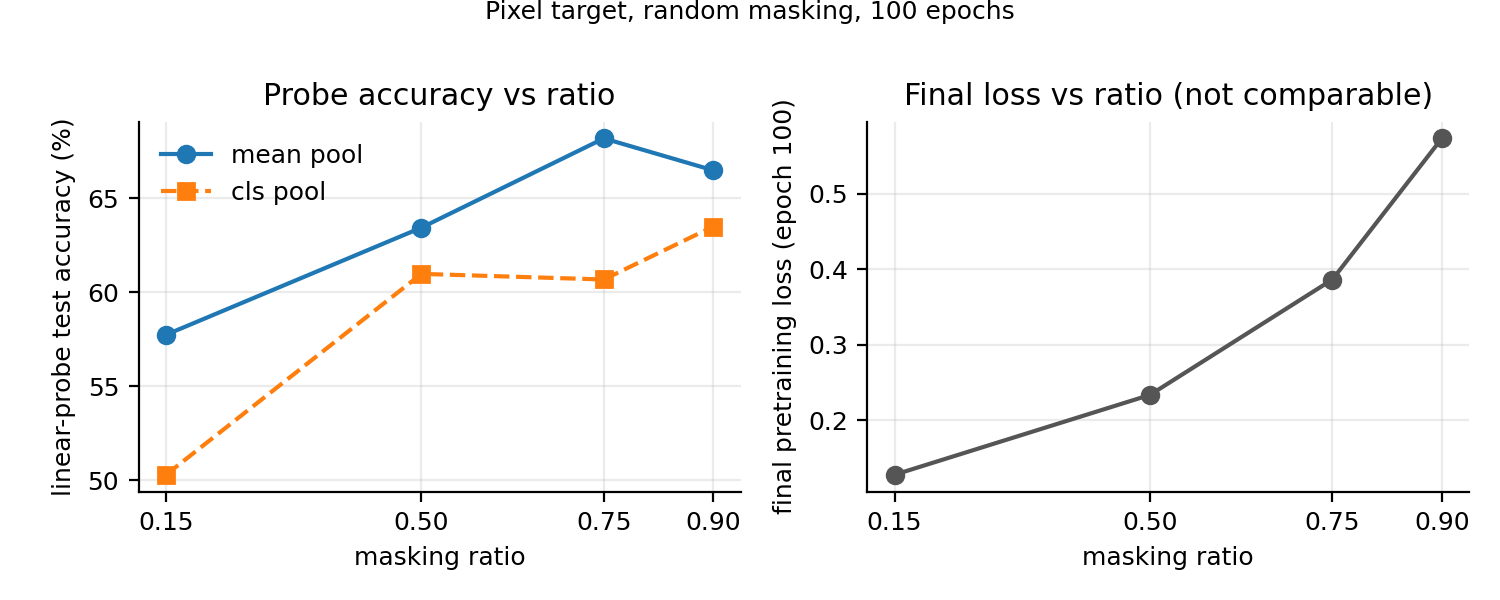

,ratio,probe mean (%),probe cls (%),final loss
run,,,,
mae_r0.15,0.15,57.74,50.29,0.1281
mae_r0.50,0.50,63.44,60.98,0.2338
mae75,0.75,68.19,60.68,0.3866
mae_r0.90,0.90,66.49,63.50,0.5736


In [3]:
display(Image("figures/fig1_ratio.png", width=760))
sweep = ["mae_r0.15", "mae_r0.50", "mae75", "mae_r0.90"]
tbl.loc[sweep, ["ratio", "probe mean (%)", "probe cls (%)", "final loss"]]

**The two panels have different shapes.**
- **Loss** rises monotonically with the ratio: 0.128 → 0.234 → 0.387 → 0.574.
- **Mean-pool probe accuracy** is an inverted U: 57.7 → 63.4 → **68.2** → 66.5, peaking at 0.75.
- **CLS probe accuracy** rises: 50.3 → 61.0 → 60.7 → 63.5.

By the loss, 0.15 is the "best" run. By what the representation can do, it is the worst.

## Q2. Why the loss is not comparable across ratios, and what changes about the prediction problem

**The loss at each ratio has a different floor.** The pixel loss averages, over hidden patches, the squared error against per-patch-standardised pixels:

$$\mathcal L_r(\theta)=\mathbb E_{X,\;S\sim\pi_r}\;\frac1{|S|}\sum_{t\in S}\tfrac1{48}\big\|q_\theta(X_{\bar S})_t-Y_t\big\|^2 .$$

Its population minimiser is the conditional mean $\mathbb E[Y_t\mid X_{\bar S}]$. So the lowest achievable value is a Bayes risk that **depends on $r$**:

$$\mathcal R^\star(r)=\mathbb E_{S\sim\pi_r}\frac1{|S|}\sum_{t\in S}\tfrac1{48}\,\mathrm{tr}\,\mathbb E\big[\mathrm{Var}(Y_t\mid X_{\bar S})\big].$$

**Raising $r$ raises the floor.** It shrinks the conditioning set: 54 → 32 → 16 → 6 visible patches out of 64. By the law of total variance, conditioning on less can only increase the expected conditional variance, so $\mathcal R^\star(r)$ grows with $r$. It also changes which patches are averaged over (see the geometry table below).

**So each ratio is a different estimation problem.** A low loss at $r = 0.15$ means the problem is easy, not that the encoder is good. The loss compares each model against its own moving yardstick. The probe instead evaluates every encoder on the same downstream task, which is why it is the comparable quantity.

**What the scale means.** With `norm_pix`, every target patch has mean 0 and unbiased variance 1 over its 48 values. Predicting 0 therefore gives a loss of exactly $47/48 = 0.979$ (checked numerically in Q5). Dividing by 0.979 gives the fraction of per-patch variance left unexplained:

| ratio | unexplained variance |
|---|---|
| 0.15 | 13% |
| 0.50 | 24% |
| 0.75 | 39% |
| 0.90 | 59% |

**What changes about the prediction problem.** The table below is computed from `masking.py` alone, with no training.
- **At $r = 0.15$:** 99.8% of hidden patches have a visible 4-neighbour, with 3.0 visible neighbours on average. The task is **interpolation**: fill a hole from the pixels around it.
- **At $r = 0.90$:** 70% of hidden patches have **no** visible neighbour, and the nearest visible patch is 2.3 steps away on average. $\mathbb E[Y_t\mid X_{\bar S}]$ now depends on what the object is and where it extends. The task becomes **inference of global structure** from six patches.
- **In between, two things happen together.** The conditioning set gets too small for local continuation, and the conditional mean becomes a blur over many plausible completions. That blur is why reconstructions get blurry and the loss keeps rising.
- **Too high a ratio leaves too little to infer from.** This is a plausible reason that 0.90 falls 1.7 points below 0.75. That gap is close to seed noise, though.

In [4]:
def mask_geometry(pattern, ratio, B=4000, g=8, seed=0):
    # Statistics of the masking distribution pi alone -- no data, no training.
    torch.manual_seed(seed)
    _, _, m = masking.make_mask(pattern, B, g, ratio, "cpu")
    hid = (m.view(B, g, g) == 1)
    vis = (~hid).float()
    pad = F.pad(vis, (1, 1, 1, 1))
    nb = pad[:, :-2, 1:-1] + pad[:, 2:, 1:-1] + pad[:, 1:-1, :-2] + pad[:, 1:-1, 2:]
    rr, cc = torch.meshgrid(torch.arange(g), torch.arange(g), indexing="ij")
    pos = torch.stack([rr.flatten(), cc.flatten()], 1)
    D = (pos[:, None] - pos[None]).abs().sum(-1).float()             # grid L1 distance
    Dm = D.expand(B, -1, -1).masked_fill(hid.view(B, 1, -1), float("inf"))
    near = Dm.min(-1).values[hid.view(B, -1)]                        # hidden -> nearest visible
    return {"pattern": pattern, "ratio": ratio,
            "visible patches": int(vis[0].sum()),
            "hidden w/ no visible 4-nbr": ((nb == 0) & hid).sum().item() / hid.sum().item(),
            "mean visible 4-nbrs of a hidden patch": nb[hid].mean().item(),
            "mean dist. to nearest visible": near.mean().item(),
            "positions ever visible": (~hid).any(0).float().mean().item()}

geom = pd.DataFrame([mask_geometry("random", r) for r in (0.15, 0.50, 0.75, 0.90)] +
                    [mask_geometry(p, 0.75) for p in ("block", "grid")])
geom

,pattern,ratio,visible patches,hidden w/ no visible 4-nbr,mean visible 4-nbrs of a hidden patch,mean dist. to nearest visible,positions ever visible
0,random,0.15,54,0.0024,2.9987,1.0024,1.0
1,random,0.50,32,0.0867,1.7756,1.0892,1.0
2,random,0.75,16,0.3569,0.8880,1.4302,1.0
3,random,0.90,6,0.7004,0.3329,2.2985,1.0
4,block,0.75,16,0.6264,0.4105,2.1356,1.0
5,grid,0.75,16,0.3913,1.1667,1.4625,0.5


## Q3. Why a locally solvable task gives a weaker global representation, and the diagnostic that shows it

**The argument.** The objective only rewards getting $\mathbb E[Y_t \mid X_{\bar S}]$ right.
- **Low ratio.** That conditional mean is almost a function of the three visible neighbours of $t$: continue the edges and colours across the hole. The encoder reaches near-Bayes loss with features that encode **local, low-level appearance and position**. The identity of the object adds almost no predictive information once the neighbours are known. The lecture's version: the objective is *indifferent* between getting the ear's exact brown right and recognising that it is an ear. Since class information is not needed for the loss, it is not learned, and a linear probe reads exactly that information.
- **High ratio.** The conditional mean depends on the object's identity, pose and extent, so the encoder must represent them.

**A mechanistic half.** The CLS token is never reconstructed. It only gets gradient insofar as the decoder uses it, which happens through attention when the patch tokens are not enough. At low ratio the visible patch tokens are enough, so the CLS is left unused.

**The diagnostic: CLS output std and effective rank over training** (plot below).
- **At $r = 0.15$, `cls_std` collapses** from 0.027 at epoch 0 to 0.008 by epoch 10, and stays near 0.007. The CLS vector becomes nearly the same for every image.
- **Its effective rank peaks** at 15 (epoch 8), then decays to 10.
- **At every $r \ge 0.5$,** effective rank keeps rising to about 18, and `cls_std` ends 1.8–5.4× larger.
- **The ordering matches the CLS probe.** Final `cls_std` runs 0.0074 < 0.0132 < 0.0313 < 0.0399. CLS-probe accuracy runs 50.3 < 61.0 ≈ 60.7 < 63.5.
- **This is shortcut-finding, not just weak features.** The 0.15 run *loses* global information while its loss keeps falling.
- **Patch locality does not separate the ratios cleanly** (0.121–0.158), so we do not rely on it.

**Is this just comparing `mae_r0.90` with `mae_r0.15`?** Essentially yes: the claim is about the sweep. Three refinements matter, though.
1. **Use all four points.** The 0.75 > 0.90 reversal shows the relationship is not "higher is always better".
2. **Compare diagnostics and probe accuracy, not the loss.** The diagnostics measure the encoder's features on the same images for every run, so they *are* comparable across ratios. The loss is not.
3. **Look at trajectories, not only final values.** The collapse of the CLS at $r = 0.15$ by epoch 10 is stronger evidence than two endpoint numbers. The gap between 0.15 and the rest is 6–11 points, far beyond the 1–2 points of seed noise.

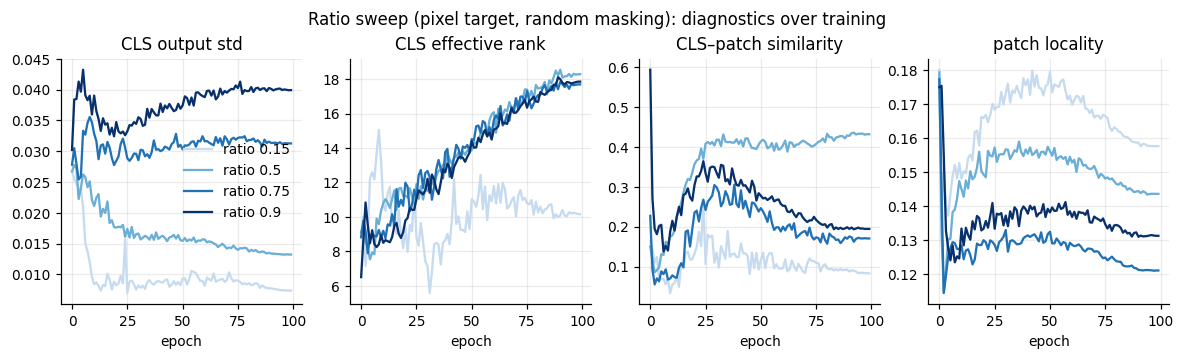

,cls_std,cls_erank,cls_patch_sim,patch_locality,probe_cls,probe_mean
mae_r0.15,0.0074,10.1567,0.0829,0.1576,50.29,57.74
mae_r0.50,0.0132,18.2885,0.4318,0.1436,60.98,63.44
mae75,0.0313,17.6944,0.1704,0.1211,60.68,68.19
mae_r0.90,0.0399,17.8541,0.1943,0.1313,63.50,66.49


In [5]:
fig, axes = plt.subplots(1, 4, figsize=(13, 2.9))
cols = [("cls_std", "CLS output std"), ("cls_erank", "CLS effective rank"),
        ("cls_patch_sim", "CLS–patch similarity"), ("patch_locality", "patch locality")]
for a, (k, t) in zip(axes, cols):
    for r, c in zip(sweep, ["#c6dbef", "#6baed6", "#2171b5", "#08306b"]):
        a.plot(M[r]["epoch"], M[r][k], c=c, label=f"ratio {probe.loc[r, 'ratio']:g}")
    a.set(title=t, xlabel="epoch")
axes[0].legend(frameon=False)
fig.suptitle("Ratio sweep (pixel target, random masking): diagnostics over training", y=1.03)
plt.show()
pd.DataFrame({k: [M[r][k].iloc[-1] for r in sweep] for k, _ in cols},
             index=sweep).assign(probe_cls=probe.loc[sweep, "acc_cls"].values,
                                 probe_mean=probe.loc[sweep, "acc_mean"].values)

## Q4. Masking pattern at ratio 0.75: block vs grid (Figure 2)

**Prediction, from the masking geometry and the lecture's interpolation argument:** block beats grid.
- **Block masking** hides 2×2 squares, so many hidden patches have no visible neighbour. That removes the interpolation shortcut, which is BEiT's reason for blockwise masking.
- **Grid masking** spreads the visible patches as evenly as possible, so interpolation stays available.
- **Expected order:** loss block > random > grid, and probe accuracy block > grid.

In [6]:
pats = ["mae75", "mae_block", "mae_grid"]
pd.DataFrame({"pattern": ["random", "block", "grid"],
              "probe mean (%)": probe.loc[pats, "acc_mean"].values,
              "probe cls (%)": probe.loc[pats, "acc_cls"].values,
              "final loss": [M[r]["loss"].iloc[-1] for r in pats],
              "cls_erank": [M[r]["cls_erank"].iloc[-1] for r in pats],
              "cls_std": [M[r]["cls_std"].iloc[-1] for r in pats],
              "cls_patch_sim": [M[r]["cls_patch_sim"].iloc[-1] for r in pats],
              "patch_locality": [M[r]["patch_locality"].iloc[-1] for r in pats]}, index=pats)

,pattern,probe mean (%),probe cls (%),final loss,cls_erank,cls_std,cls_patch_sim,patch_locality
mae75,random,68.19,60.68,0.3866,17.6944,0.0313,0.1704,0.1211
mae_block,block,68.52,65.99,0.5565,22.0162,0.0423,0.2077,0.1357
mae_grid,grid,65.19,64.76,0.3394,18.7719,0.0175,0.3327,0.1422


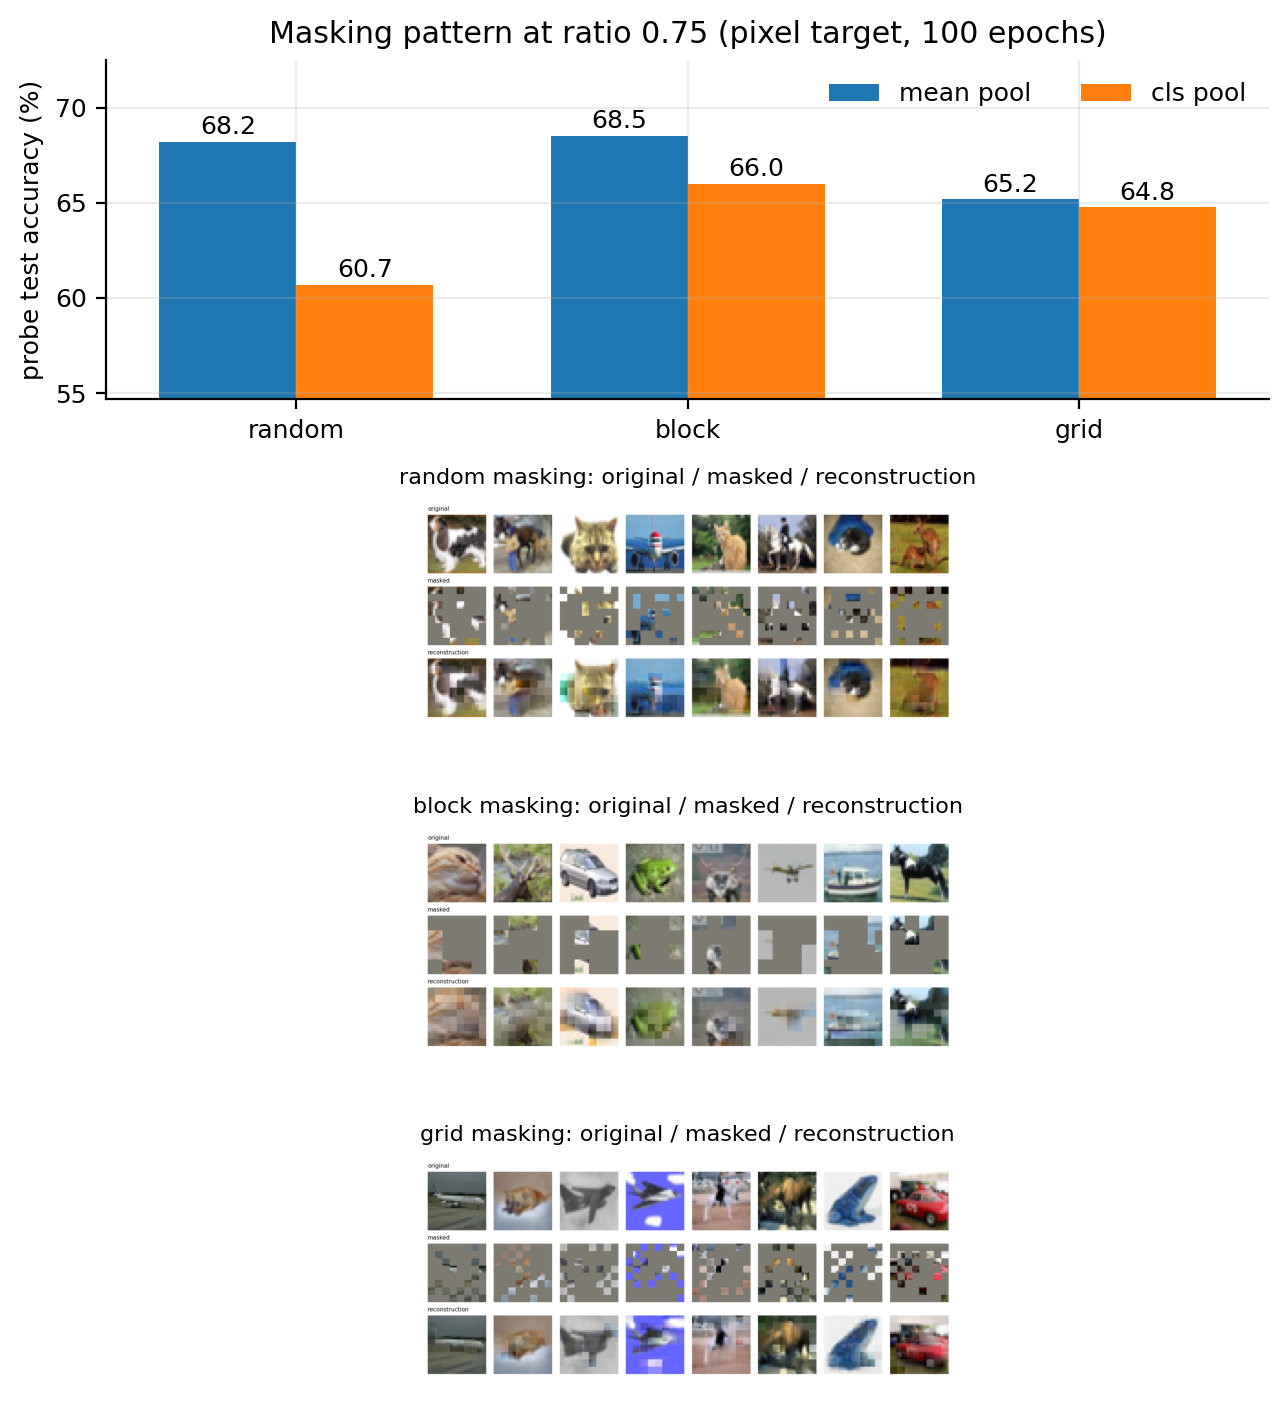

,pattern,ratio,visible patches,hidden w/ no visible 4-nbr,mean visible 4-nbrs of a hidden patch,mean dist. to nearest visible,positions ever visible
2,random,0.75,16,0.3569,0.8880,1.4302,1.0
4,block,0.75,16,0.6264,0.4105,2.1356,1.0
5,grid,0.75,16,0.3913,1.1667,1.4625,0.5


In [7]:
display(Image("figures/fig2_patterns.png", width=760))
geom[geom["ratio"] == 0.75]

**Result (seed 0, one run per pattern): block won, as predicted.**
- **Mean pool:** block 68.5% vs grid 65.2%, a gap of 3.3 points.
- **CLS:** block 66.0% vs grid 64.8%, a gap of 1.2 points.
- **Random** sits at 68.2% (mean pool).

**Caveat: this is a single pretraining seed per pattern.** The assignment puts run-to-run noise at 1–2 points. The CLS gap is inside that range and the mean-pool gap is only just outside it. We did not repeat the runs with a second seed, so "block beats grid" is suggestive, not established. The loss ordering and the masking geometry below are a separate line of evidence, and they point the same way.

**Why block beats grid.** The loss ordering confirms the mechanism: grid 0.339 < random 0.387 < block 0.557. That is exactly the order of **how many visible neighbours a hidden patch has on average**: grid 1.17, random 0.89, block 0.41.
- **This statistic of $\pi$ separates block from grid at equal ratio**, and it needs no training.
- **The "no visible neighbour" fraction does not separate grid from random** (39% vs 36%). Grid does not leave *more* hidden patches isolated. It packs the visible patches so that the hidden patches next to them get as many visible neighbours as possible, which is the best possible setting for interpolation.
- **The reconstruction grids show the same thing.** Grid reconstructions are the sharpest, and block reconstructions are blurry 2×2 squares.
- **The easier the local problem, the weaker the representation**, which is the Q3 argument again.

**A second effect we did not predict, honestly diagnosed.** The grid mask in `masking.py` is not random over positions:
- **How it works.** Scores are checkerboard parity + 0.5·U(0,1), and the 16 lowest scores are kept. All 16 always land on the 32 *even-parity* cells ("positions ever visible" = 0.50 in the table).
- **The consequence.** During pretraining the encoder **never processes a patch at an odd-parity position**. At probe time it sees all 64 patches, half of them at positions it never saw as input.
- **Why this hurts mean pooling most.** This train/test shift should hurt mean-pooled patch features, which average over those tokens, more than the CLS. Consistent with that, grid's mean–CLS gap is 0.4 points, against 2.5 for block and 7.5 for random.
- **What we can conclude.** Grid's deficit is plausibly part "easier interpolation" and part "positional shift", and these runs cannot separate the two. A grid variant that randomises the checkerboard parity per image would.

**Block vs random** (68.5 vs 68.2 mean pool) is within noise. Hiding more local context than random masking already does at 0.75 bought little on the mean-pool probe. The CLS probe differs much more (66.0 vs 60.7).

---
# Part 2(b) — the target $Y$

## Q5. The constant solution

**The loss.** For the feature target, each hidden patch contributes

$$\ell_t = \|\hat q_t - \hat y_t\|^2 = 2 - 2\langle \hat q_t, \hat y_t\rangle \;\ge 0,
\qquad \hat q_t = \tfrac{q_\theta(X_{\bar S})_t}{\|\cdot\|},\quad
\hat y_t = \tfrac{f_\xi(X)_t - \text{center}}{\|\cdot\|},$$

where $f_\xi$ is the EMA teacher. Equality holds iff $\hat q_t = \hat y_t$.

**The constant solution.**
- The encoder outputs the same vector $c$ for every patch of every image. For example, set the final LayerNorm's weight to 0 and its bias to $c$.
- The teacher is an EMA of the student's parameters, so it converges to the same constant map $f_\xi \equiv c$.
- The decoder outputs $c$ for every hidden patch.

**It minimises the feature loss.** Without centering, $\hat y_t = \hat q_t = c/\|c\|$, so $\ell_t = 0$ for every image, patch and mask. Since $\mathcal L \ge 0$, this is a **global minimum**, and the gradient is zero too.
- **The starter code's centering does not change this.** Its running center converges to $c/2$ (shown in Q7), so $\hat y = \text{normalize}(c/2) = c/\|c\|$ again.
- **Checked numerically below:** the loss is 0 to floating-point precision (≤ 1e-7) with centering off *and* on.

**Why the pixel loss has no such solution.**
- **The target cannot move.** $Y_t$ is a fixed function of the input (the standardised pixels of patch $t$), not of $\theta$, so it cannot come to meet the prediction.
- **A constant prediction $q \equiv a$ pays the full variance.** Its loss is $\mathbb E\|Y_t - a\|^2/48 \ge \mathrm{tr}\,\mathrm{Cov}(Y_t)/48 = 47/48 \approx 0.979$, minimised at $a = \mathbb E Y_t = 0$.
- **The minimiser must depend on the input.** It is $\mathbb E[Y_t\mid X_{\bar S}]$, which varies because images differ.
- **The only way to lower the pixel loss is to carry information about the image.** In the feature loss both sides are functions of the parameters ($\theta$ and its average $\xi$). That makes "agree by both saying nothing" available.

In [8]:
_, test_ds = data.get_eval_datasets("./data")
imgs = next(iter(DataLoader(test_ds, batch_size=32, shuffle=False)))[0].to(device)
c = torch.randn(192, device=device)

def make_collapsed(center, eps=0.0, dino_center=False, seed=1):
    # Feature-target model whose encoder AND teacher output c (+ eps-sized variation), decoder outputs c.
    torch.manual_seed(seed)
    m = MaskedModel(target="feature", center=center).to(device)
    if dino_center:
        m._feature_target = dino_feature_target.__get__(m)
    with torch.no_grad():
        w = eps * torch.randn(192, device=device)
        for enc in (m.encoder, m.teacher):
            enc.norm.weight.copy_(w); enc.norm.bias.copy_(c)
        m.decoder.head.weight.zero_(); m.decoder.head.bias.copy_(c)
    return m

def dino_feature_target(self, imgs):
    # Textbook DINO centering: running mean of the RAW teacher outputs (used in Q7 for comparison).
    _, p = self.teacher.features(imgs)
    out = p - self.center
    self.center.mul_(self.center_m).add_(p.mean(dim=(0, 1), keepdim=True), alpha=1 - self.center_m)
    return F.normalize(out, dim=-1)

res = []
for center in (False, True):
    m = make_collapsed(center)
    with torch.no_grad():
        spread = (m.encoder.features(imgs)[1] - c).abs().max().item()
        for _ in range(150):                      # let the running center converge
            loss, _, _ = m(imgs, ratio=0.75)
    res.append({"model": f"feature target, constant encoder, centering={'on' if center else 'off'}",
                "max |output - c|": spread, "masked loss": loss.item()})

# pixel target: best constant predictor (0) vs the trained MAE on the same batch
pm = MaskedModel(target="pixel").to(device)
with torch.no_grad():
    pm.decoder.head.weight.zero_(); pm.decoder.head.bias.zero_()
    res.append({"model": "pixel target, constant prediction 0", "masked loss": pm(imgs, ratio=0.75)[0].item()})
    ck = torch.load("runs/mae75/encoder.pt", map_location=device)
    tm = MaskedModel(target="pixel").to(device)
    tm.encoder.load_state_dict(ck["encoder"]); tm.decoder.load_state_dict(ck["decoder"])
    tm.eval()
    res.append({"model": "pixel target, trained mae75", "masked loss": tm(imgs, ratio=0.75)[0].item()})
pd.DataFrame(res)

C:\Users\aarus\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\torchvision\datasets\cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


,model,max |output - c|,masked loss
0,"feature target, constant encoder, centering=off",0.0,1.1921e-07
1,"feature target, constant encoder, centering=on",0.0,0.0000e+00
2,"pixel target, constant prediction 0",NaN,9.7915e-01
3,"pixel target, trained mae75",NaN,4.8502e-01


## Q6. The collapse panel: when the loss says success and when the diagnostics say something is wrong (Figure 3)

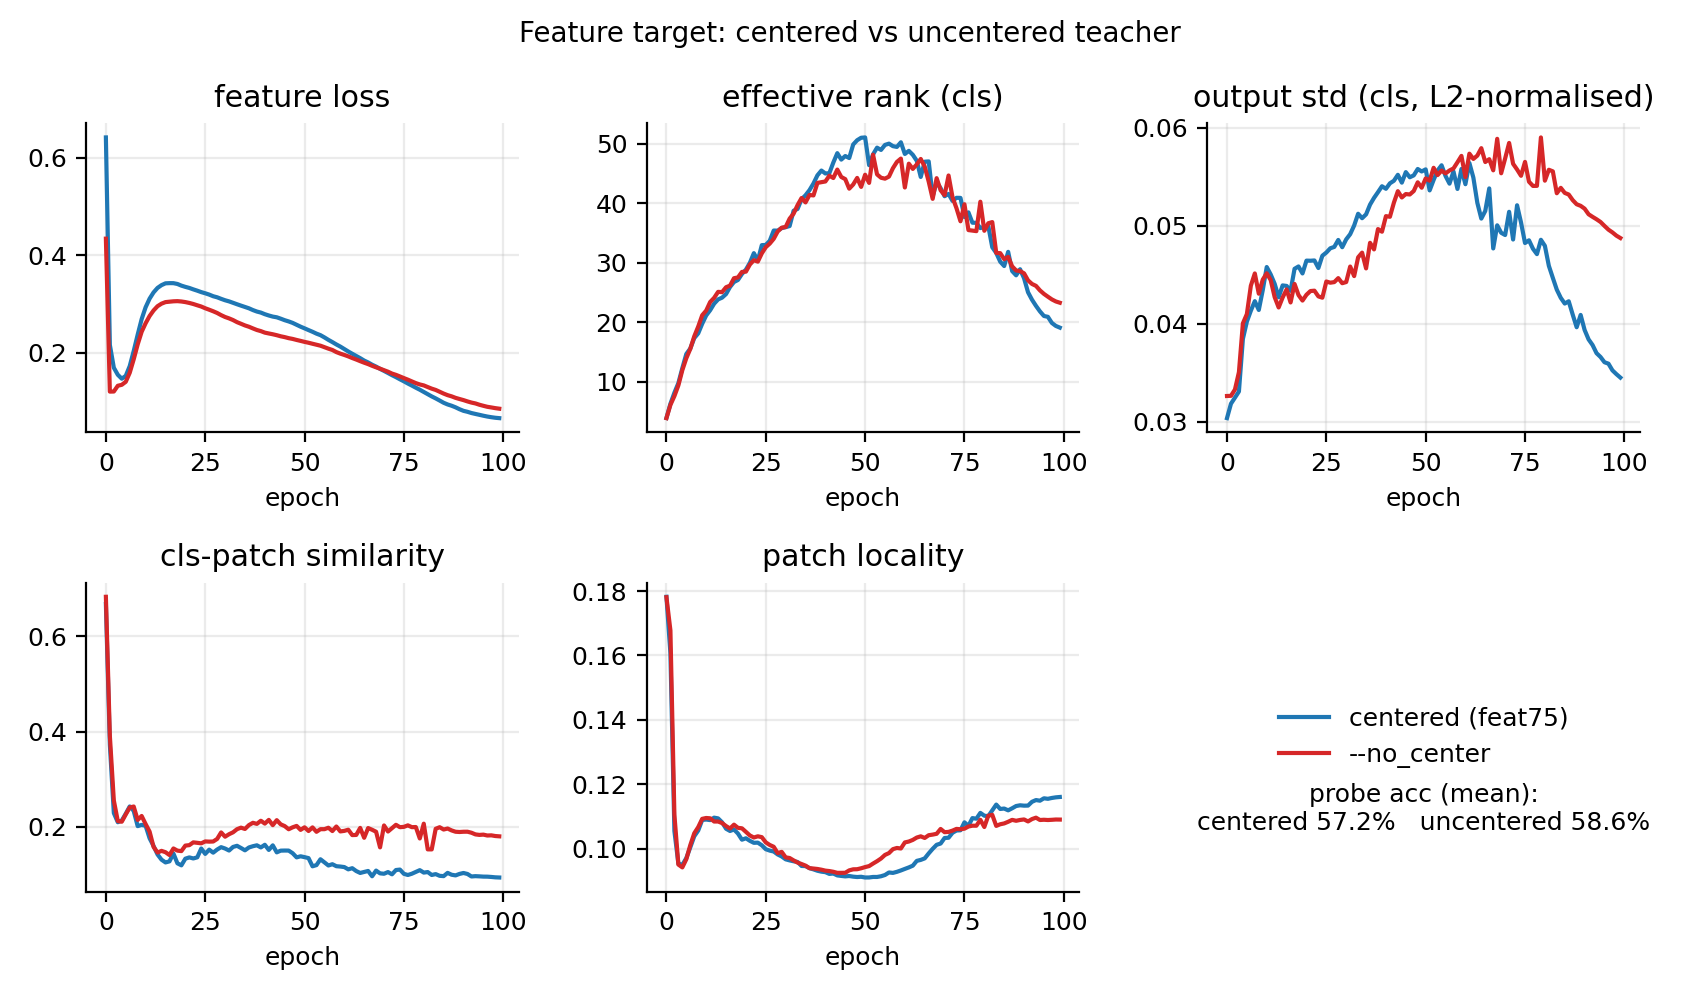

,centered (feat75),uncentered (feat_nocenter)
loss minimum (epoch),99,99
early loss low point (epoch),4,1
loss / erank there,0.146 / 12.3,0.120 / 6.1
loss next this low (epoch),74,84
erank peak (epoch),50,52
erank peak -> final,51.1 -> 19.1 (-63%),48.2 -> 23.3 (-52%)
loss at peak -> final,0.250 -> 0.065 (-74%),0.218 -> 0.085 (-61%)
cls_std peak (epoch),61,79
cls_std peak -> final,0.0564 -> 0.0345 (-39%),0.0590 -> 0.0488 (-17%)
patch locality best (epoch),50,44


In [9]:
display(Image("figures/fig3_collapse.png", width=820))

def key_epochs(run):
    m = M[run]
    early = m.iloc[:10]["loss"].idxmin()                          # early low point of the loss
    later_below = m.index[(m.index > early + 5) & (m["loss"] < m.loc[early, "loss"])]
    pk = m["cls_erank"].idxmax(); sd = m["cls_std"].idxmax(); lo = m["patch_locality"].idxmin()
    f = m.iloc[-1]
    return {"loss minimum (epoch)": int(m["loss"].idxmin()),
            "early loss low point (epoch)": int(early),
            "  loss / erank there": f"{m.loc[early, 'loss']:.3f} / {m.loc[early, 'cls_erank']:.1f}",
            "  loss next this low (epoch)": int(later_below[0]) if len(later_below) else None,
            "erank peak (epoch)": int(pk),
            "  erank peak -> final": f"{m.loc[pk, 'cls_erank']:.1f} -> {f['cls_erank']:.1f} ({f['cls_erank']/m.loc[pk, 'cls_erank']-1:+.0%})",
            "  loss at peak -> final": f"{m.loc[pk, 'loss']:.3f} -> {f['loss']:.3f} ({f['loss']/m.loc[pk, 'loss']-1:+.0%})",
            "cls_std peak (epoch)": int(sd),
            "  cls_std peak -> final": f"{m.loc[sd, 'cls_std']:.4f} -> {f['cls_std']:.4f} ({f['cls_std']/m.loc[sd, 'cls_std']-1:+.0%})",
            "patch locality best (epoch)": int(lo),
            "  locality best -> final": f"{m.loc[lo, 'patch_locality']:.3f} -> {f['patch_locality']:.3f} ({f['patch_locality']/m.loc[lo, 'patch_locality']-1:+.0%})"}

pd.DataFrame({"centered (feat75)": key_epochs("feat75"),
              "uncentered (feat_nocenter)": key_epochs("feat_nocenter")})

**The loss alone would have declared success at epoch 99, the last epoch.** In both runs the feature loss falls monotonically from epoch 17 (centered) / 19 (uncentered) and reaches its minimum at epoch 99, so the loss-based choice is "train to the end, keep the final checkpoint". There is also an earlier trap.
- **The early low point.** At epoch 1 (uncentered) and epoch 4 (centered) the loss had already fallen 70–80%.
- **The loss does not get that low again until epoch 84 (uncentered) / 74 (centered).** If you had stopped on that early plateau you would have declared success with a CLS effective rank of 6–12 out of 192. Those early epochs are *easy* agreement with a nearly uninformative teacher.

**The diagnostics say something is wrong from about epoch 50.**
- **Effective rank of the CLS features peaks** at epoch 50 (centered, 51.1) and epoch 52 (uncentered, 48.2). It then falls by 63% and 52%, to 19.1 and 23.3 at epoch 99.
- **In the centered run, `cls_std` peaks** at epoch 61 and falls by about 40% by epoch 99. The uncentered run's peaks later, at epoch 79, and falls less.
- **Patch locality is best** at epoch 50 / 44 and then degrades by 27% / 18%.

**The gap is about 50 epochs**, and that is the point of the exercise.
- **The loss's biggest improvements happen during the decline.** The centered loss falls 74% (0.250 → 0.065) between epochs 50 and 99, exactly while the representation loses more than half its effective dimensions.
- **Agreement gets easier as both sides get simpler.** The feature loss measures agreement with a target that is itself a function of the parameters, so a falling feature loss is consistent both with learning and with **dimensional collapse**. Only the diagnostics tell them apart.
- **Why the effective rank is the right signal here.** The collapse is *partial*: `cls_std` stays at 0.035–0.049 and never approaches 0, so this is not a constant representation. That is why the effective rank, which is scale-invariant and blind to a fully constant output, is the informative diagnostic here, with `cls_std` confirming the representation is not constant.
- **Limitation:** we did not save the epoch-50 checkpoints, so we cannot report the probe accuracy at the diagnostics' best epoch.

## Q7. What does centering do? Is the collapsed solution still a minimiser, or is it just harder to find?

**Probe accuracy of the uncentered run: 58.7% (mean pool) / 58.0% (CLS).** The centered `feat75` gets 57.2% / 55.7%, so removing centering did **not** hurt. The uncentered run also ends with a *higher* `cls_std` (0.049 vs 0.035) and effective rank (23.3 vs 19.1).

**What the code actually does.** `methods.py` updates the center with the batch mean of the *already-centered* features:

$$\text{center} \leftarrow m\,\text{center} + (1-m)\,(\mu - \text{center}) \;\Longrightarrow\; \text{center}^\star = \mu/2 .$$

So it subtracts only **half** the mean teacher feature. Textbook DINO uses $\text{center} \leftarrow m\,\text{center} + (1-m)\,\mu$, with fixed point $\mu$. The first cell below confirms $\|\text{center}\|/\|\mu\| = 0.500$ on the trained `feat75` teacher.

In [10]:
ck = torch.load("runs/feat75/encoder.pt", map_location=device)
m = MaskedModel(target="feature", center=True).to(device)
m.teacher.load_state_dict(ck["encoder"])
with torch.no_grad():
    mu = m.teacher.features(imgs)[1].mean(dim=(0, 1))
    for _ in range(150):
        m._feature_target(imgs)
print(f"trained feat75 teacher:  |center| / |mu| = {(m.center.flatten().norm() / mu.norm()).item():.4f},"
      f"  cos(center, mu) = {F.cosine_similarity(m.center.flatten(), mu, dim=0).item():.4f}")

rows = []
for label, dino in (("starter-code centering (center -> mu/2)", False), ("DINO centering (center -> mu)", True)):
    for eps in (0.0, 1e-2):
        mm = make_collapsed(center=True, eps=eps, dino_center=dino)
        with torch.no_grad():
            for _ in range(150):
                loss, _, _ = mm(imgs, ratio=0.75)
            y = mm._feature_target(imgs).reshape(-1, 192)
            Y = y[torch.randperm(y.shape[0], device=device)[:500]]
        rows.append({"centering": label, "distance from collapse (eps)": eps,
                     "loss of constant student": loss.item(),
                     "mean pairwise cos of targets": (Y @ Y.T).mean().item()})
pd.DataFrame(rows)

trained feat75 teacher:  |center| / |mu| = 0.5000,  cos(center, mu) = 1.0000


,centering,distance from collapse (eps),loss of constant student,mean pairwise cos of targets
0,starter-code centering (center -> mu/2),0.00,0.0000,1.0000
1,starter-code centering (center -> mu/2),0.01,0.0003,0.9997
2,DINO centering (center -> mu),0.00,0.1411,1.0000
3,DINO centering (center -> mu),0.01,2.0008,0.0090


**Reading the evidence.**

1. **Existence: centering does not make the collapsed solution stop being a minimiser.**
   - **The starter code's centering:** a constant encoder gives the target $\text{normalize}(c - c/2) = c/\|c\|$, so the loss is exactly 0. That is proved above and checked numerically.
   - **Even correct DINO centering adds no penalty term.** The student's loss is still $2 - 2\cos$, which is minimised by matching *any* target, constant or not.
   - **At exact collapse the DINO target becomes $0/0$.** The surviving direction is whatever transient or rounding residual $c - \text{center}$ leaves (the nonzero DINO loss at eps = 0 above). A constant student can match that too, so a degenerate minimiser remains.

2. **Dynamics: correct centering makes collapse *repelling*.** Just next to collapse (eps = 0.01) the two versions behave completely differently.
   - **DINO centering** subtracts the shared component and L2-normalises what is left, which blows the tiny image-specific deviations up to unit length. The targets become diverse (mean cosine ≈ 0.01), and a constant student scores loss ≈ 2.0, about as bad as it gets. The gradient therefore pushes *away* from collapse.
   - **The starter's half-centering** leaves the targets identical (cosine ≈ 1.000, loss ≈ 0). Near collapse it neither repels nor attracts more than no centering.
   - **So centering's real effect is on attractiveness**, the optimiser's ability to find or stay at the collapsed point, not on existence. This is DINO's "centering acts across images": it is built from batch statistics of the *target*, not a term in the student's loss.

3. **What our runs support, carefully.**
   - **Our runs cannot show centering preventing collapse.** The uncentered run did not collapse in 100 epochs, and the two runs' diagnostic curves overlap until about epoch 50.
   - **Collapse was already non-attractive without centering.** That is consistent with the BYOL-style asymmetry that remains: stop-gradient on the teacher, a slow EMA ($m = 0.996$), a predictor (the decoder), and asymmetric inputs (the student sees 25% of the patches, the teacher sees all of them).
   - **Centering did not prevent the late dimensional decline either.** Both runs suffered it, and in principle it cannot: centering is a rank-one correction (subtract one mean vector) that leaves the rest of the spectrum alone.
   - **Supported:** centering, in this code and in general, does not remove the collapsed minimiser. At best (correctly implemented) it makes the optimiser less likely to approach it.
   - **Not supported by our data:** that centering is what kept `feat75` from collapsing.
   - **A fair test** would use the textbook update, train long enough (or with weaker asymmetry) for the uncentered run to collapse, and use at least two seeds.

---
## Q8. Required diagnostics for every run

Values are taken at the final epoch (99), on the fixed held-out batch logged by `train.py`, plus the effective-rank peak over training.
- **Effective rank** is scale-invariant, so it cannot see a constant representation.
- **Output std** can see a constant representation; ≈ 0 means complete collapse.
- **CLS–patch similarity** and **patch locality** describe the *patch* features, which the linear probe is blind to.

In [11]:
def diag_row(run):
    m = pd.read_csv(f"runs/{run}/metrics.csv"); f = m.iloc[-1]
    acc = {"mean": probe.loc[run, "acc_mean"], "cls": probe.loc[run, "acc_cls"]}
    return {"run": run,
            "effective rank (cls)": f["cls_erank"],
            "erank peak @ epoch": f"{m['cls_erank'].max():.1f} @ {int(m['cls_erank'].idxmax())}",
            "output std (cls)": f["cls_std"], "CLS-patch sim": f["cls_patch_sim"],
            "patch locality": f["patch_locality"],
            "probe mean (%)": acc["mean"], "probe cls (%)": acc["cls"], "final loss": f["loss"]}

diag = pd.DataFrame([diag_row(r) for r in RUNS]).set_index("run")
diag.to_csv("figures/table_diagnostics.csv")
diag

,effective rank (cls),erank peak @ epoch,output std (cls),CLS-patch sim,patch locality,probe mean (%),probe cls (%),final loss
run,,,,,,,,
mae_r0.15,10.1567,15.1 @ 8,0.0074,0.0829,0.1576,57.74,50.29,0.1281
mae_r0.50,18.2885,18.5 @ 90,0.0132,0.4318,0.1436,63.44,60.98,0.2338
mae75,17.6944,17.8 @ 90,0.0313,0.1704,0.1211,68.19,60.68,0.3866
mae_r0.90,17.8541,18.1 @ 89,0.0399,0.1943,0.1313,66.49,63.50,0.5736
mae_block,22.0162,22.5 @ 90,0.0423,0.2077,0.1357,68.52,65.99,0.5565
mae_grid,18.7719,18.8 @ 96,0.0175,0.3327,0.1422,65.19,64.76,0.3394
feat75,19.0752,51.1 @ 50,0.0345,0.0936,0.1160,57.23,55.72,0.0651
feat_nocenter,23.2677,48.2 @ 52,0.0488,0.1800,0.1090,58.65,58.04,0.0845


---
# Part 3 — Connect

## 2. The target as a choice of equivalence

**A target defines an equivalence.** A target $Y = g(\text{patch})$ defines the relation $p \sim p' \iff g(p) = g(p')$, and the loss is **indifferent to every difference inside a class**. The lecture puts it this way: augmentation chooses what *input* variation to ignore, and the target chooses what *target* variation to ignore. A finer relation means the objective asks about more detail; a coarser one makes it more invariant.

**Where each target sits:**
- **MAE (pixels, as in our code).** With `norm_pix`, $g(p) = (p - \bar p)/s_p$. Two patches are equivalent iff they differ by a per-patch brightness shift and contrast scale ($p' = a p + b$, $a > 0$). This is almost the identity, **the finest relation**. It treats every pixel-level difference beyond local brightness and contrast as worth predicting, and it is fixed by hand.
- **BEiT.** $g = \tau(p) \in \{1, \dots, 8192\}$: a partition into 8192 cells, **fixed in advance** by an external tokenizer. Two slightly different browns can share a code, and then the objective stops asking about that difference. It is coarser than pixels, but the classes cannot adapt as the representation improves.
- **iBOT / our feature target.** $g_\xi(p) = \text{normalize}(f_\xi(p \mid \text{whole image}) - \text{center})$. The equivalence classes are the level sets of the teacher's feature directions. They are:
  - **contextual:** the same pixels in two images can be inequivalent, and different pixels equivalent;
  - **scale-free:** the normalisation discards scale;
  - **learned and moving:** they change as $\xi$ is updated. This is the **coarsest and only adaptive** relation of the three.

**On a scale:** pixels (finest, fixed) ≺ BEiT tokens (8192 classes, fixed) ≺ iBOT features (learned, can coarsen without limit). Our MAE target sits at the fine end and our feature target at the coarse, adaptive end.

**Our data show the adaptive relation coarsening during training.** After epoch 50 the effective rank of the feature run fell from about 51 to 19: more and more images map to the same few directions. On this small model and 100-epoch schedule the fine target won the linear probe clearly (68.2% vs 57.2%), the opposite of the large-scale literature. A coarse target only helps if its classes line up with semantics, and that needs a good teacher, which a small model in 100 epochs does not provide.

**What a target that is *too* invariant looks like.**
- **The extreme.** The trivial relation, where every patch is equivalent to every other: $g \equiv$ const. The target carries no information and the objective is solved by the constant solution of Q5, which **is collapse**.
- **The milder, practically relevant version.** A target invariant to everything except the image's global content, so that all patches *within* an image are equivalent. That rewards patch tokens that simply copy the image vector: CLS–patch similarity goes to 1 and patch locality is lost. This is the dense collapse DINOv3 runs into (next question).

## 3. Global versus dense structure

**Existence vs attractiveness, again.** As with BYOL, the constant solution **exists** as a global minimiser of the feature objective: loss exactly 0, verified in Q5, and still true with this code's centering (Q7). What keeps training away from it is the **dynamics**, not the loss landscape. Our uncentered run did not collapse at all in 100 epochs.

**How the anti-collapse mechanism differs from Mini-Project I.**
- **Contrastive objectives** (negatives / uniformity) change **existence**. The repulsion term is in the student's loss, so the constant map is no longer a minimiser.
- **BYOL** keeps the constant minimiser and avoids it through **dynamics**: predictor, stop-gradient and EMA target.
- **The iBOT-style objective inherits BYOL's asymmetry**: EMA teacher, stop-gradient, decoder as predictor, plus a new input asymmetry (the student sees 25% of the patches, the teacher the whole image). It adds **centering**, which differs from both earlier mechanisms in two ways:
  - **It acts on the target, through batch statistics, not as a term in the student's loss.** Near collapse it re-normalises the image-specific deviations to unit size (Q7), so it shapes *attractiveness* rather than existence.
  - **It is defined at one level, the batch mean over all patches of all images.** It stops every patch of every image sharing one direction, but says **nothing about whether the patches within one image become alike**. Neither does the probe.

**Why `patch_locality` can degrade while probe accuracy holds steady.** Let $P\in\mathbb R^{N\times d}$ be the $\ell_2$-normalised patch features of one image.
- **The probe sees only first moments.** It reads either the CLS vector or the mean $\tfrac1N\mathbf 1^\top P$.
- **`patch_locality` sees second moments.** It is a function of the **Gram matrix** $G = PP^\top$ (which patches are most similar to which), mapped onto grid positions.
- **The two can change independently.** Many $P$ share the same mean but have completely different $G$. The cell below takes `feat75`'s patch tokens and randomly permutes them within each image. The mean-pooled feature, and so the probe's input, is **unchanged to machine precision**, while patch locality jumps from 0.12 to 0.38, which is chance level (0.375 for random positions on an 8×8 grid). The probe is *structurally* blind to the dense structure.
- **What DINOv3 measured.** Patch features drift toward the global vector, so CLS–patch similarity rises. That can leave classification untouched, or even help it by making the mean cleaner.

**What our runs show:**
- **Feature runs.** After epoch 50, patch locality degraded by 27% (centered) and 18% (uncentered) while the loss kept improving. CLS–patch similarity did *not* rise in these runs (centered 0.16 → 0.09), so the degradation is not DINOv3's CLS-drift mechanism. It goes together with the effective-rank decline: patches losing diversity rather than copying the CLS.
- **Pixel runs.** The DINOv3 signature does appear: CLS–patch similarity rose from 0.13 → 0.43 at ratio 0.50 and from 0.08 → 0.33 with grid masking, and those runs still probe at 63–65%.
- **Limitation:** we only have final-epoch probes, so we cannot show probe accuracy flat over the same epochs as the locality decline. Across the eight runs, final locality and probe accuracy are only weakly related (below).

**The link to Gram anchoring.** DINOv3 adds $\mathcal L_{\text{Gram}} = \|G_{\text{student}} - G_{\text{anchor}}\|_F^2$, using an earlier checkpoint whose dense features were still good.
- **It regularises exactly what our diagnostic watches and the probe ignores.** $G$ is the object `patch_locality` is computed from.
- **It does not freeze the features.** $G$ is invariant to rotations of the feature space, $(PR)(PR)^\top = PP^\top$, so anchoring preserves the *pairwise relations between patches* while leaving the global representation free to keep improving.
- **For our runs,** the natural anchor is the feature run's epoch-50 checkpoint, where patch locality and effective rank are at their best. Gram anchoring from there targets precisely the decline in Figure 3.
- **As the lecture stresses, it is a repair applied late, not a removal of the cause.** The diagnostics tell you when it is needed; the loss and the probe do not.

In [12]:
ck = torch.load("runs/feat75/encoder.pt", map_location=device)
enc = MaskedModel(target="feature").encoder.to(device)
enc.load_state_dict(ck["encoder"]); enc.eval()
x = next(iter(DataLoader(test_ds, batch_size=256, shuffle=True)))[0].to(device)
with torch.no_grad():
    _, P = enc.features(x)
    perm = torch.stack([torch.randperm(P.shape[1], device=device) for _ in range(P.shape[0])])
    Pp = torch.gather(P, 1, perm.unsqueeze(-1).expand_as(P))   # shuffle patch tokens within each image
    print(f"max |mean-pool(P) - mean-pool(P shuffled)| = {(P.mean(1) - Pp.mean(1)).abs().max().item():.2e}")
    print(f"patch locality: original = {metrics.patch_locality(P, 8):.3f},  "
          f"shuffled = {metrics.patch_locality(Pp, 8):.3f}")

fin = pd.DataFrame({"patch_locality": [M[r]["patch_locality"].iloc[-1] for r in RUNS],
                    "probe mean (%)": probe["acc_mean"].values}, index=RUNS)
print(f"\nacross the 8 runs: corr(final patch locality, probe mean accuracy) = "
      f"{fin.corr().iloc[0, 1]:+.2f}")
fin.T

max |mean-pool(P) - mean-pool(P shuffled)| = 2.38e-07
patch locality: original = 0.116,  shuffled = 0.380

across the 8 runs: corr(final patch locality, probe mean accuracy) = +0.09


,mae_r0.15,mae_r0.50,mae75,mae_r0.90,mae_block,mae_grid,feat75,feat_nocenter
patch_locality,0.1576,0.1436,0.1211,0.1313,0.1357,0.1422,0.116,0.109
probe mean (%),57.7400,63.4400,68.1900,66.4900,68.5200,65.1900,57.230,58.650


---
## Required figures checklist

| required | where | status |
|---|---|---|
| (1) probe accuracy and final loss vs masking ratio, two panels | `figures/fig1_ratio.png` (Q1) | ✓ |
| (2) three-pattern comparison at fixed ratio, with reconstruction grids | `figures/fig2_patterns.png` (Q4); grids in `runs/{mae75,mae_block,mae_grid}/recon.png` | ✓ |
| (3) collapse panel, centered vs uncentered (loss, effective rank, output std, CLS–patch sim on shared axes) | `figures/fig3_collapse.png` (Q6) | ✓ |
| table of linear-probe accuracy over all eight runs | top of this notebook; `figures/table_probe.md` / `.csv` | ✓ |
| per-run diagnostics table | Q8; `figures/table_diagnostics.csv` | ✓ |
| Part 1 figures (reconstruction at 75%, cls/mean probes for both targets) | teammate | assumed complete |
| `metrics.csv` from every run | `runs/*/metrics.csv` | ✓ |

In [13]:
need = ["figures/fig1_ratio.png", "figures/fig2_patterns.png", "figures/fig3_collapse.png",
        "figures/table_probe.md", "figures/table_diagnostics.csv",
        "runs/mae75/recon.png", "runs/mae_block/recon.png", "runs/mae_grid/recon.png"] + \
       [f"runs/{r}/metrics.csv" for r in RUNS]
missing = [p for p in need if not os.path.exists(p)]
print("all required files present" if not missing else f"MISSING: {missing}")

all required files present


---
*AI-use acknowledgement (required by the syllabus):* describe here how generative AI was used. For example: running the experiments, drafting the analysis, and code for figures and tables. Also state that the group reviewed and is responsible for the interpretation.